# Análise dos experimentos

Lê `scripts/experiments/*/{runs,timeline,probe,summary}.csv` produzidos por
`scripts/experiment.py` e mostra tabelas e gráficos.

Pré-requisitos: `pip install pandas matplotlib jupyter`, e pelo menos um cenário
já executado (`scripts/experiment.py baseline --seeds 5`).

Execute as células em ordem. O DataFrame `runs` agrega todas as execuções;
`ttr` agrega os resumos de falha. Ajuste `SCENARIO` na última célula para
inspecionar outro diretório em `scripts/experiments/`.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
while not (root / "compose.yaml").exists() and root != root.parent:
    root = root.parent
EXP = root / "scripts" / "experiments"

frames = []
for f in sorted(EXP.glob("*/runs.csv")):
    df = pd.read_csv(f)
    df["experiment"] = f.parent.name
    frames.append(df)
runs = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

print(f"{len(runs)} runs from {runs['experiment'].nunique() if not runs.empty else 0} experiments")
runs.head()


46 runs from 7 experiments


,tag,nodes,clients,ops,seed,duration_s,throughput_ops_s,p50_ms,p95_ms,p99_ms,retry_pct,attempts_per_op,attempts_p99,wrong_leader_pct,linearizable,experiment
0,baseline,3,8,400,1,0.236,1696.68,4.308,7.352,8.834,2.0,1.02,2.0,1.96,ok,baseline
1,baseline,3,8,400,2,0.243,1643.59,4.474,7.209,9.412,2.0,1.02,2.0,1.96,ok,baseline
2,baseline,3,8,400,3,0.253,1581.69,4.550,7.710,8.348,2.0,1.02,2.0,1.96,ok,baseline
3,baseline,3,8,400,4,0.257,1557.76,4.802,8.313,9.379,2.0,1.02,2.0,1.96,ok,baseline
4,baseline,3,8,400,5,0.216,1850.62,4.061,8.127,9.718,2.0,1.02,2.0,1.96,ok,baseline


In [2]:
METRICS = ["throughput_ops_s", "p50_ms", "p95_ms", "p99_ms", "retry_pct", "attempts_per_op"]

if runs.empty:
    print("no experiments yet: run scripts/experiment.py first")
else:
    table = runs.groupby(["experiment", "tag"])[METRICS].agg(["mean", "std"]).round(2)
    display(table)


throughput_ops_s           p50_ms        p95_ms  \
                                         mean      std    mean   std    mean   
experiment  tag                                                                
baseline    baseline                  1899.88   799.98    4.25  0.87    7.16   
kill-leader kill-after                2555.51  1130.06    3.26  1.60    6.30   
            kill-during               1924.57   732.87    2.67  0.49   11.93   
netem       netem-50ms-2%               41.25     2.43  155.16  0.28  291.25   
partition   partition-after           1225.41   501.43    2.84  0.86    7.31   
            partition-during          1750.17  1463.61    3.67  1.59   80.42   
sweep-n3    n3                        2175.17   766.92    3.70  1.18    6.18   
sweep-n5    n5                        1794.66   987.05    3.03  0.54    6.25   
sweep-n7    n7                        1952.60   361.78    3.77  0.60    6.88   

                                      p99_ms         retry_pct        \
                                 std    mean     std      mean   std   
experiment  tag                                                        
baseline    baseline            1.50    8.44    1.80      2.00  0.00   
kill-leader kill-after          2.17    9.88    3.67      1.60  0.89   
            kill-during        10.05   82.65  148.37      1.20  1.10   
netem       netem-50ms-2%      28.85  413.88   63.15      2.00  0.00   
partition   partition-after     1.96  210.48  206.16      2.00  0.00   
            partition-during  127.99  182.87  298.51      0.67  1.15   
sweep-n3    n3                  1.23    7.92    2.62      0.00  0.00   
sweep-n5    n5                  1.41  422.80  893.45      2.00  0.00   
sweep-n7    n7                  1.88   15.27   13.60      0.00  0.00   

                             attempts_per_op        
                                        mean   std  
experiment  tag                                     
baseline    baseline                    1.02  0.00  
kill-leader kill-after                  1.02  0.01  
            kill-during                 1.01  0.01  
netem       netem-50ms-2%               1.02  0.00  
partition   partition-after             7.04  8.25  
            partition-during            1.01  0.01  
sweep-n3    n3                          1.00  0.00  
sweep-n5    n5                          1.08  0.00  
sweep-n7    n7                          1.00  0.00

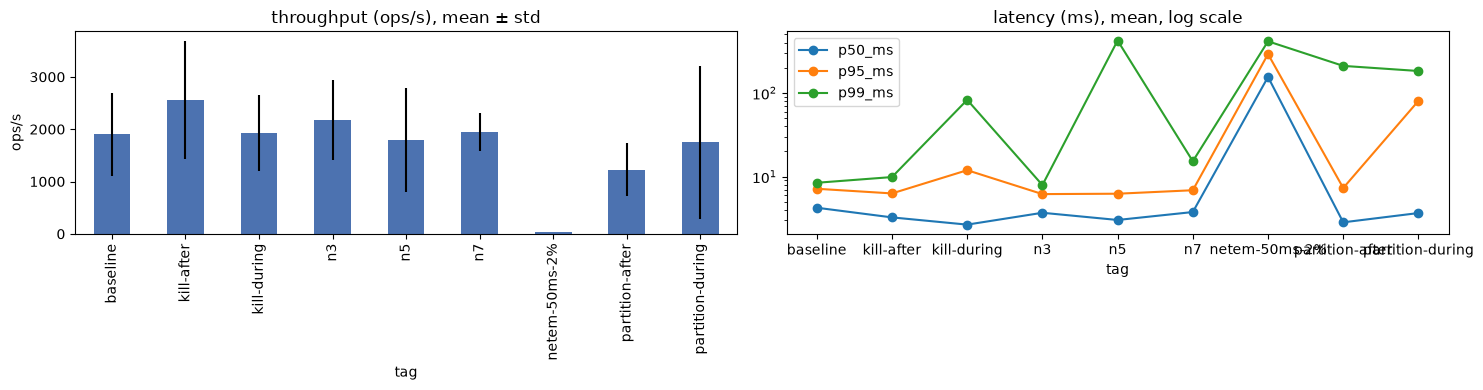

In [3]:
if not runs.empty:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    mean = runs.groupby("tag")["throughput_ops_s"].mean()
    std = runs.groupby("tag")["throughput_ops_s"].std().fillna(0)
    mean.plot.bar(yerr=std, ax=axes[0], color="#4C72B0")
    axes[0].set_title("throughput (ops/s), mean ± std")
    axes[0].set_ylabel("ops/s")

    for m in ["p50_ms", "p95_ms", "p99_ms"]:
        runs.groupby("tag")[m].mean().plot(ax=axes[1], marker="o", label=m)
    axes[1].set_yscale("log")
    axes[1].set_title("latency (ms), mean, log scale")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


,seed,fault_unix_ms,time_to_elect_ms,ttr_service_ms,ttr_replica_ms,pre_term,new_term,converged,experiment
0,1,1794243328126,431,1846,521,50,51,True,kill-leader
1,2,1794243332236,705,1915,509,51,52,True,kill-leader
2,3,1794243337041,429,1838,251,52,53,True,kill-leader
3,4,1794243341661,483,1886,562,53,54,True,kill-leader
4,5,1794243346489,486,1854,499,54,55,True,kill-leader
5,1,1794243718556,516,2065,10,1,10,False,partition
6,2,1794243755301,151,1565,-1,1,95,False,partition
7,3,1794243851652,381,1266,10,1,10,False,partition


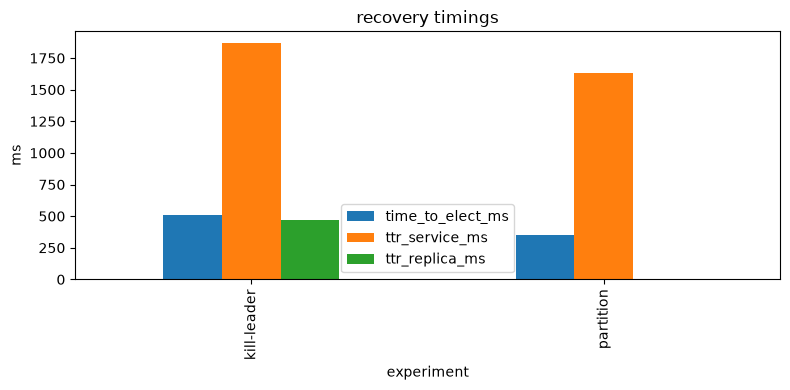

In [4]:
NUMERIC = ["time_to_elect_ms", "ttr_service_ms", "ttr_replica_ms"]

ttr_frames = []
for f in sorted(EXP.glob("*/summary.csv")):
    df = pd.read_csv(f)
    if set(NUMERIC).issubset(df.columns):
        df["experiment"] = f.parent.name
        ttr_frames.append(df)
ttr = pd.concat(ttr_frames, ignore_index=True) if ttr_frames else pd.DataFrame()

if ttr.empty:
    print("no fault runs yet (kill-leader / partition)")
else:
    for col in NUMERIC:
        ttr[col] = pd.to_numeric(ttr[col], errors="coerce")
    display(ttr)
    mean = ttr.groupby("experiment")[NUMERIC].mean()
    ax = mean.plot.bar(figsize=(8, 4))
    ax.set_ylabel("ms")
    ax.set_title("recovery timings")
    plt.tight_layout()
    plt.show()


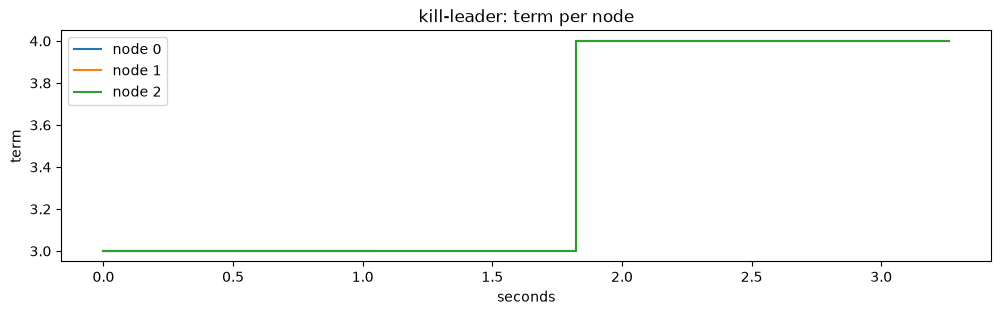

IndexError: list index out of range

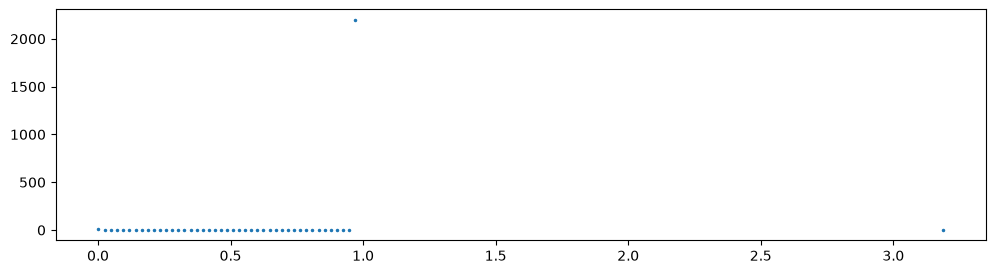

In [5]:
SCENARIO = "kill-leader"   # any directory under scripts/experiments/

tl_files = sorted((EXP / SCENARIO).glob("timeline*.csv"))
if tl_files:
    tl = pd.read_csv(tl_files[-1])
    tl["t_s"] = (tl["t_ms"] - tl["t_ms"].min()) / 1000
    fig, ax = plt.subplots(figsize=(12, 3))
    for node, g in tl.groupby("node"):
        ax.step(g["t_s"], g["term"], where="post", label=f"node {node}")
    ax.set(xlabel="seconds", ylabel="term", title=f"{SCENARIO}: term per node")
    ax.legend()
    plt.show()

pr_files = sorted((EXP / SCENARIO).glob("probe*.csv"))
if pr_files:
    pr = pd.read_csv(pr_files[-1])
    pr["t_s"] = (pr["start_ns"] - pr["start_ns"].min()) / 1e9
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(pr["t_s"], pr["lat_ms"], ".", ms=3)

    sm_path = EXP / SCENARIO / "summary.csv"
    if sm_path.exists():
        sm = pd.read_csv(sm_path)
        if "fault_unix_ms" in sm.columns:
            seed = int(pr_files[-1].stem.split("-")[1])
            row = sm[sm["seed"] == seed] if "seed" in sm.columns else sm.iloc[:1]
            if not row.empty and pd.notna(row["fault_unix_ms"].iloc[0]):
                fault_s = (row["fault_unix_ms"].iloc[0] * 1e6 - pr["start_ns"].min()) / 1e9
                ax.axvline(fault_s, color="crimson", ls="--", label="fault")
                ax.legend()

    ax.set_yscale("log")
    ax.set(xlabel="seconds", ylabel="write latency (ms)", title=f"{SCENARIO}: probe writes")
    plt.show()


## Como ler

* `baseline` deve ter `retry_pct ~ 0` e zero mudanças de líder; qualquer coisa
  diferente indica contenção ou timeouts agressivos.
* Em `netem`, o throughput cai e p99 sobe, mas `linearizable` continua `ok`.
* Em `kill-leader`, `time_to_elect` deve ficar perto do `ElectionTimeout`
  (500 ms + jitter) e `ttr_service` inclui o timeout HTTP do cliente (~2 s).
* `ttr_replica` cresce com o atraso do nó e com o tamanho do log; com
  `MAX_RAFT_STATE` baixo o nó atrasado é recuperado por `InstallSnapshot`.
* Term/leader no timeline mostrando `leader_id = -1` e termos crescendo sem
  parar é o problema de *disruptive server* descrito em `scripts/README.md`.
